# k-Nearest Neighbours from First Principles: Classifying 100,000 Sky Objects

This notebook builds nearest-neighbour classification from the ground up, then applies it to real astronomy data.

1. **Theory:** what is the *lowest possible* training error, and why is "zero training error" not the same as a good model?
2. **From scratch:** a k-NN search and classifier in plain Python + NumPy with a custom distance function and deterministic tie-breaking, validated against scikit-learn.
3. **Real data:** classifying 100,000 objects from the Sloan Digital Sky Survey (SDSS DR17) as **galaxies, stars or quasars** from their brightness in five colour bands and their redshift. Result: **96.2% test accuracy**.

Tools: NumPy, pandas, scikit-learn, matplotlib.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
})
BLUE, ORANGE, GREY = "#2563eb", "#f97316", "#9ca3af"

## Part 1: The best possible hypothesis on training data

**Setting.** Features $x \in \mathbb{Z}^d$ (integer coordinates), labels $y \in \mathbb{R}^J$, and the $L_1$ loss

$$\ell(y, y') = \|y - y'\|_1 = \sum_{j=1}^{J} |y_j - y'_j|.$$

Given data $(x_1, y_1), \dots, (x_N, y_N)$, the empirical error of a hypothesis $h$ is

$$R_N(h) = \frac{1}{N} \sum_{n=1}^{N} \ell\big(h(x_n), y_n\big).$$

If $h$ can be *any* function, only its values at the training points matter. When a feature vector $x$ appears once, the best prediction is simply its label, giving zero loss. When the **same $x$ appears several times with different labels**, no function can match them all. The best single prediction under $L_1$ loss is the **coordinate-wise median** of those labels, because the median minimises a sum of absolute deviations.

In [2]:
def h_best(x, X, Y):
    # all training points that share the feature vector x
    matches = np.all(X == x, axis=1)
    # under L1 loss the best single prediction is the coordinate-wise median of their labels
    return np.median(Y[matches], axis=0)


def best_err(X, Y):
    loss_L1 = lambda y, yp: np.linalg.norm(y - yp, ord = 1)
    s = 0.0
    for n in range(len(X)):
        s += loss_L1(Y[n], h_best(X[n], X, Y))
    return s / len(X)

**Two constructed examples** show what the minimum error depends on.

* `X_1c`: the point $[1, 0]$ appears twice with labels 0 and 1. No hypothesis can be right about both, so the error floor is $(0.5 + 0.5)/5 = 0.2$.
* `X_1d`: every feature vector is distinct, so a lookup table fits the data perfectly with error $0$. That says nothing about how it would do on *new* points, which is the classic overfitting trap.

In [3]:
X_1c = np.array([[1, 0], [1, 0], [2, 0], [3, 0], [4, 0]], dtype=float)
Y_1c = np.array([[0.0], [1.0], [0.0], [0.0], [0.0]])

X_1d = np.array([[1, 0], [2, 0], [3, 0], [4, 0], [5, 0]], dtype=float)
Y_1d = np.array([[1.0], [2.0], [3.0], [4.0], [5.0]])

print(f"best_err(X_1c, Y_1c) = {best_err(X_1c, Y_1c):.1f}   ← irreducible error from conflicting labels")
print(f"best_err(X_1d, Y_1d) = {best_err(X_1d, Y_1d):.1f}   ← perfect memorisation, not proof of a good model")

best_err(X_1c, Y_1c) = 0.2   ← irreducible error from conflicting labels
best_err(X_1d, Y_1d) = 0.0   ← perfect memorisation, not proof of a good model


**Why the median matters.** A simpler idea is to return the label of the *first* matching training point. My first version did exactly that. It gives the right answer when a point repeats at most twice, but not in general:

In [4]:
X_rep = np.array([[7, 7], [7, 7], [7, 7]], dtype=float)
Y_rep = np.array([[1.0], [0.0], [0.0]])

first_match = lambda x, X, Y: Y[np.where(np.all(X == x, axis=1))[0][0]]
err_first = np.mean([np.abs(Y_rep[n] - first_match(X_rep[n], X_rep, Y_rep)).sum() for n in range(3)])

print(f"first-match prediction: {first_match(X_rep[0], X_rep, Y_rep)} → error {err_first:.3f}")
print(f"median prediction:      {h_best(X_rep[0], X_rep, Y_rep)} → error {best_err(X_rep, Y_rep):.3f}")

first-match prediction: [1.] → error 0.667
median prediction:      [0.] → error 0.333


## Part 2: k-NN from scratch

**Distance.** Instead of the usual Euclidean distance, this search uses a *mixed-exponent* distance that treats even and odd coordinates differently:

$$d(u, v) = \sum_{i=0}^{d-1} |u_i - v_i|^{\,p(i)}, \qquad p(i) = \begin{cases} 2 & i \text{ odd} \\ 1 & i \text{ even.} \end{cases}$$

Even-indexed features are compared linearly, as in Manhattan distance, while odd-indexed features penalise large gaps quadratically. Being able to plug in a custom metric like this matters whenever features have different meanings or noise levels.

**Deterministic tie-breaking.** The neighbours are returned sorted by distance. Points at *exactly* the same distance come back in increasing index order, so results are reproducible.

In [5]:
def my_knn(x, X, k):
    N, d = X.shape

    distances = []
    for n in range(N):
        dist = 0.0
        for i in range(d):
            p = 2 if i % 2 == 1 else 1
            dist += abs(x[i] - X[n, i]) ** p
        distances.append((dist, n))

    # sort by distance, then by index so ties are broken deterministically
    distances.sort(key = lambda t: (t[0], t[1]))

    return [distances[j][1] for j in range(k)]

**Classifier with a principled tie-break.** The prediction is the most common label among the $k$ neighbours. If several labels are equally common, the one held by the **closest** neighbour wins. Scanning the neighbours in distance order and returning the first label with the top count does exactly that.

In [6]:
def my_knn_predict(x, X, k, y):
    neighbour_indices = my_knn(x, X, k)
    neighbour_labels = [y[i] for i in neighbour_indices]

    counts = {}
    for label in neighbour_labels:
        counts[label] = counts.get(label, 0) + 1

    max_count = max(counts.values())

    # neighbours are in distance order, so the first label with the top count is the closest one
    for label in neighbour_labels:
        if counts[label] == max_count:
            return label

### Testing the implementation

**1. Tie-breaking rules.** The neighbours' labels in distance order are `c, b, a, a, b`. Both `a` and `b` get two votes, and `b` has the closer neighbour, so `b` should win.

In [7]:
X_toy = np.array([[1, 0], [2, 0], [3, 0], [4, 0], [5, 0]], dtype=float)
y_toy = ["c", "b", "a", "a", "b"]
x_query = np.array([0.0, 0.0])

print("neighbours:", my_knn(x_query, X_toy, 5))
print("prediction:", my_knn_predict(x_query, X_toy, 5, y_toy))

# equal distances must come back in increasing index order
X_tie = np.array([[2, 0], [1, 0], [-1, 0], [0, 1]], dtype=float)
print("tie order: ", my_knn(x_query, X_tie, 4), "(indices 1, 2 and 3 are all at distance 1)")

neighbours: [0, 1, 2, 3, 4]
prediction: b
tie order:  [1, 2, 3, 0] (indices 1, 2 and 3 are all at distance 1)


**2. Cross-check against scikit-learn.** I give scikit-learn's `NearestNeighbors` the same custom metric and compare the neighbour lists for 100 random queries.

In [8]:
from sklearn.neighbors import NearestNeighbors

rng = np.random.default_rng(0)
X_rand = rng.normal(size=(300, 4))
queries = rng.normal(size=(100, 4))

mixed = lambda u, v: np.sum(np.abs(u - v) ** np.where(np.arange(len(u)) % 2 == 1, 2, 1))
nn = NearestNeighbors(n_neighbors=7, metric=mixed, algorithm="brute").fit(X_rand)
_, sk_idx = nn.kneighbors(queries)

agree = sum(my_knn(q, X_rand, 7) == list(row) for q, row in zip(queries, sk_idx))
print(f"Identical 7-NN lists for {agree}/{len(queries)} queries")

Identical 7-NN lists for 100/100 queries


## Part 3: Classifying galaxies, stars and quasars (SDSS DR17)

The [Stellar Classification Dataset (SDSS17)](https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17) holds 100,000 spectroscopically labelled objects. I use six features:

| Feature | Meaning |
|---|---|
| `u, g, r, i, z` | brightness (magnitude) through five filters, ultraviolet to infrared |
| `redshift` | how far the object's light is stretched by cosmic expansion, a proxy for distance |

Missing values are coded as −9999 and dropped (one row).

In [9]:
astro = pd.read_csv("data/star_classification.csv")
astro = astro.replace(-9999, np.nan).dropna()

print(f"{len(astro):,} objects")
astro["class"].value_counts(normalize=True).round(3).rename("share")

99,999 objects


class
GALAXY    0.594
STAR      0.216
QSO       0.190
Name: share, dtype: float64

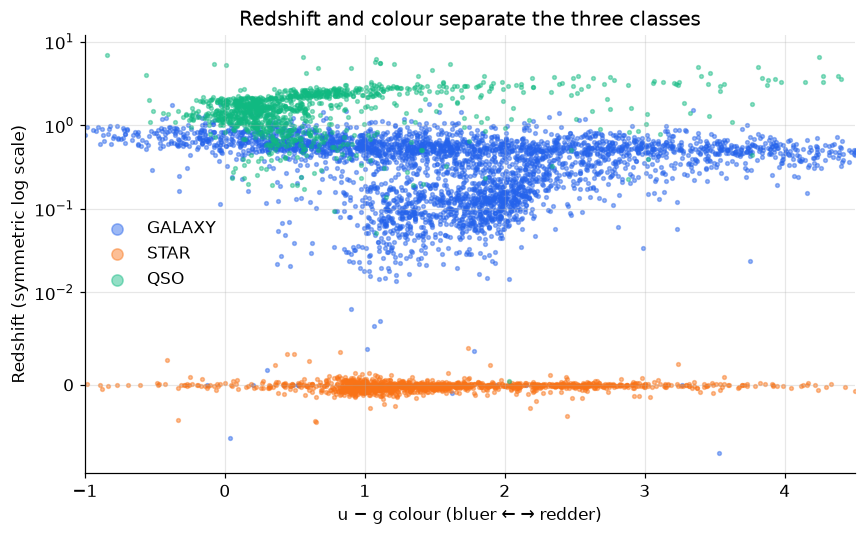

In [10]:
sample = astro.sample(6000, random_state=1)
palette = {"GALAXY": BLUE, "STAR": ORANGE, "QSO": "#10b981"}

fig, ax = plt.subplots(figsize=(8, 5))
for cls, color in palette.items():
    s = sample[sample["class"] == cls]
    ax.scatter(s["u"] - s["g"], s["redshift"], s=6, alpha=0.45, color=color, label=cls)
ax.set_yscale("symlog", linthresh=0.01)
ax.set_xlim(-1, 4.5)
ax.set_xlabel("u − g colour (bluer ← → redder)")
ax.set_ylabel("Redshift (symmetric log scale)")
ax.set_title("Redshift and colour separate the three classes")
ax.legend(markerscale=3, frameon=False)
plt.tight_layout()
plt.show()

Redshift does most of the work. **Stars** sit at redshift ≈ 0 because they are inside our own galaxy. **Galaxies** cluster below about 1, and **quasars**, bright cores of very distant galaxies, reach redshifts of 2 to 7. The colour axis helps separate quasars from galaxies where their redshifts overlap.

### Model selection: choosing k

Features are z-score standardised inside a pipeline, so the scaler is fitted on training data only and nothing leaks from the test set. I hold out 20% for testing and try $k = 2, \dots, 6$.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X = astro[["u", "g", "r", "i", "z", "redshift"]]
y = astro["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=True,
    random_state=3383
)

scores = {}
for k in range(2, 7):
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    pipeline.fit(X_train, y_train)
    scores[k] = pipeline.score(X_test, y_test)

astro_scores = pd.Series(scores)
astro_scores.rename("test accuracy").round(4)

2    0.9548
3    0.9615
4    0.9616
5    0.9618
6    0.9614
Name: test accuracy, dtype: float64

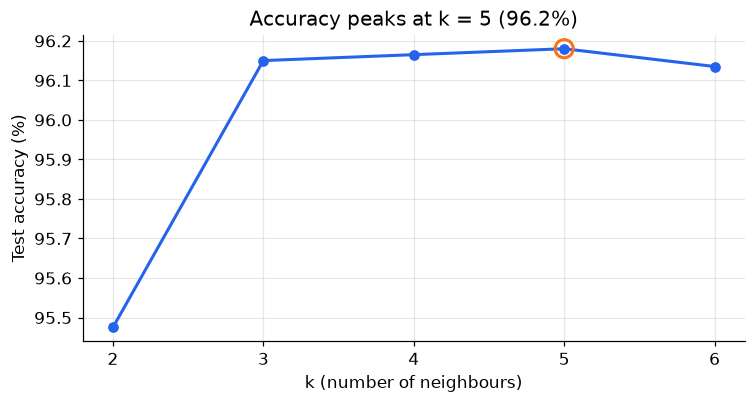

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(astro_scores.index, astro_scores.values * 100, marker="o", color=BLUE, lw=2)
best_k = astro_scores.idxmax()
ax.scatter([best_k], [astro_scores[best_k] * 100], s=140, facecolors="none", edgecolors=ORANGE, lw=2, zorder=3)
ax.set_xticks(astro_scores.index)
ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("Test accuracy (%)")
ax.set_title(f"Accuracy peaks at k = {best_k} ({astro_scores[best_k]:.1%})")
plt.tight_layout()
plt.show()

With $k=2$ the model reacts too much to individual noisy neighbours. From $k=3$ on, accuracy plateaus around 96.1–96.2%.

### Why scaling matters

k-NN is purely distance-based, so a feature on a larger numeric scale dominates the distance. Magnitudes range over roughly 10–30 while redshift mostly stays below 1, so without scaling the magnitudes dominate and redshift's contribution shrinks:

In [13]:
unscaled = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train)
print(f"k = {best_k} without scaling: {unscaled.score(X_test, y_test):.1%}")
print(f"k = {best_k} with z-scores:   {astro_scores[best_k]:.1%}")

k = 5 without scaling: 95.0%
k = 5 with z-scores:   96.2%


Scaling cuts the error rate from 5.0% to 3.8%, about **a quarter fewer mistakes**, for one line of code.

### Final model and error analysis

In [14]:
astro_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(
        n_neighbors=best_k
    ))
])

astro_pipe.fit(X_train, y_train)
y_pred = astro_pipe.predict(X_test)
print(f"Test accuracy: {astro_pipe.score(X_test, y_test):.4f}")

Test accuracy: 0.9618


              precision    recall  f1-score   support

      GALAXY      0.974     0.963     0.968     11999
         QSO      0.956     0.931     0.944      3775
        STAR      0.934     0.987     0.959      4226

    accuracy                          0.962     20000
   macro avg      0.955     0.960     0.957     20000
weighted avg      0.962     0.962     0.962     20000



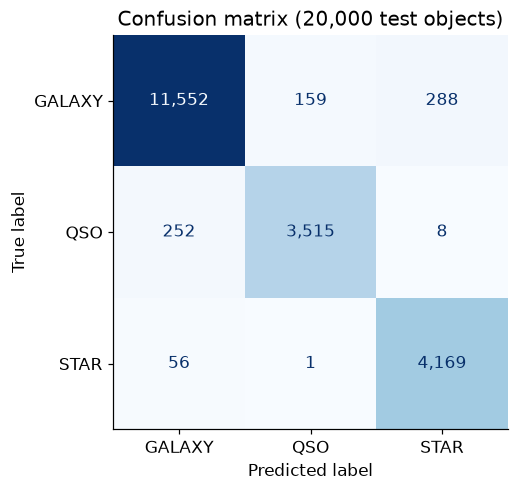

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

print(classification_report(y_test, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(5.5, 4.6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, ax=ax, cmap="Blues", colorbar=False, values_format=",")
ax.set_title("Confusion matrix (20,000 test objects)")
ax.grid(False)
plt.tight_layout()
plt.show()

In [16]:
cm = pd.crosstab(y_test, y_pred)
qso_missed = cm.loc["QSO"].drop("QSO")
print(f"Quasars misclassified: {qso_missed.sum()} of {cm.loc['QSO'].sum()}, "
      f"of which {qso_missed['GALAXY']} were labelled galaxies")

Quasars misclassified: 260 of 3775, of which 252 were labelled galaxies


## Results and takeaways

* **96.2% accuracy** on 20,000 held-out objects with a simple, interpretable model, against 59% for always guessing "galaxy".
* **Stars are easiest** (recall 98.7%), since redshift ≈ 0 gives them away. **Quasars are hardest** (recall 93.1%): 252 of the 260 missed quasars were labelled galaxies, where the two classes' redshifts overlap.
* **Preprocessing matters more than tuning here:** z-scoring removes about a quarter of the errors (95.0% → 96.2%), while choosing any k between 3 and 6 changes accuracy by less than 0.05 points.
* **The from-scratch implementation** matches scikit-learn exactly on 100/100 random queries with a custom metric, including deterministic tie-breaking.

**Next steps:** compare against a tree ensemble such as gradient boosting, which handles unscaled features and the class imbalance naturally, and use cross-validation rather than a single split to choose k.